# Predicting customer churn and prioritizing outreach

A reproducible comparison of logistic regression, random forest, and gradient
boosting on the [Kaggle bank churn dataset](https://www.kaggle.com/datasets/shubh0799/churn-modelling).

**Question:** Which customers should a fictional bank contact when it can reach
only 10% of its customer base? We compare model quality and then explore this
assumed outreach capacity. Observed churn is not the same as preventable churn;
this dataset cannot measure the causal benefit of contacting someone.

This notebook replaces the three earlier model-specific notebooks. Shared,
tested helpers live in `churn_workflow.py` and `threshold_analysis.py`; setup and
data download instructions are in README.md. Run all cells from the repository
root using Python 3.11 and requirements.txt. Searches use two workers.

### Evaluation plan

1. Reserve a reproducible stratified 30% test partition.
2. On the remaining 70%, tune each model using five-fold pipeline CV, selecting
   by average precision. No imputation, encoding, scaling, or parameter tuning
   sees test rows.
3. Report each selected model once on the test partition at a fixed 0.5 threshold.
4. Separately explore outreach budgets using nested CV **only on training rows**.
   The demonstration uses gradient boosting and a 10% capacity, chosen after
   exploratory comparisons rather than an independent confirmatory assessment.

These data have been analyzed previously. A corrected protocol does not turn them
into a new external validation cohort: results remain exploratory.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from churn_workflow import (
    load_data, split_data, tune_model, evaluate_model, evaluate_baseline,
    plot_evaluation,
)
from threshold_analysis import nested_training_scores, capacity_table, plot_capacity

X, y = load_data()
X_train, X_test, y_train, y_test = split_data(X, y)
assert set(X_train.index).isdisjoint(X_test.index)
print(f'Training customers: {len(X_train):,}; test customers: {len(X_test):,}')
print(f'Training churn prevalence: {y_train.mean():.2%}')

Training customers: 7,000; test customers: 3,000
Training churn prevalence: 20.37%


## Explore training data

Identifiers and surnames are excluded from predictors. All remaining predictors
are retained. The pipeline imputes numerical missing values, scales numerical
features, and imputes/encodes categories separately within every training fold.
Logistic regression has an intercept and tuned regularization; trees capture
nonlinear effects without the old Box–Tidwell feature-removal rule.

In [2]:
display(X_train.describe(include='all'))
display(X_train.isna().sum().rename('Missing training values'))
X_train['Age'].hist(bins=25)
plt.xlabel('Customer age (training data only)')
plt.ylabel('Customers')
plt.show()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography,Gender
count,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000,7000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,France,Male
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3489,3866
mean,650.562429,38.998429,5.010571,76314.462261,1.533000,0.707429,0.517000,99466.316050,NaN,NaN
std,96.539456,10.574949,2.891900,62374.574114,0.584162,0.454976,0.499747,57451.411246,NaN,NaN
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,NaN,NaN
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.000000,0.000000,50202.460000,NaN,NaN
50%,652.000000,37.000000,5.000000,96846.565000,1.000000,1.000000,1.000000,98710.275000,NaN,NaN
75%,717.000000,44.000000,8.000000,127789.347500,2.000000,1.000000,1.000000,148580.725000,NaN,NaN


CreditScore        0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Geography          0
Gender             0
Name: Missing training values, dtype: int64

<Figure size 640x480 with 1 Axes>

## Select models using training-only cross-validation

Average precision focuses on ranking the minority churn class. ROC AUC and
accuracy are additional diagnostics. Search scores reflect parameter selection,
not an independent final assessment. The candidate grids are intentionally small,
with deterministic seeds, and can be expanded later using training data only.

In [3]:
searches = {}
cv_tables = []
for name in ['logistic', 'forest', 'boosting']:
    search = tune_model(name, X_train, y_train)
    searches[name] = search
    table = pd.DataFrame(search.cv_results_)
    table.insert(0, 'model', name)
    cv_tables.append(table)
    print(name, 'selected parameters:', search.best_params_)
    print(f'  {search.n_splits_} folds × {len(table)} candidates completed')
cv_results = pd.concat(cv_tables, ignore_index=True)
display(cv_results[['model', 'params', 'mean_test_average_precision',
                    'std_test_average_precision', 'mean_test_roc_auc']]
        .sort_values(['model', 'mean_test_average_precision'], ascending=[True, False]))

logistic selected parameters: {'model__C': 1.0, 'model__class_weight': None}
  5 folds × 6 candidates completed


forest selected parameters: {'model__max_depth': None, 'model__min_samples_leaf': 5}
  5 folds × 4 candidates completed


boosting selected parameters: {'model__max_depth': 3, 'model__n_estimators': 100}
  5 folds × 4 candidates completed


,model,params,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc
12,boosting,"{'model__max_depth': 3, 'model__n_estimators':...",0.693357,0.019863,0.860117
13,boosting,"{'model__max_depth': 3, 'model__n_estimators':...",0.689017,0.022064,0.856970
11,boosting,"{'model__max_depth': 1, 'model__n_estimators':...",0.657746,0.028714,0.841084
10,boosting,"{'model__max_depth': 1, 'model__n_estimators':...",0.646616,0.033489,0.837414
9,forest,"{'model__max_depth': None, 'model__min_samples...",0.666694,0.014425,0.852150
8,forest,"{'model__max_depth': None, 'model__min_samples...",0.655397,0.015650,0.843115
7,forest,"{'model__max_depth': 5, 'model__min_samples_le...",0.654666,0.023747,0.842478
6,forest,"{'model__max_depth': 5, 'model__min_samples_le...",0.651858,0.019217,0.842367
2,logistic,"{'model__C': 1.0, 'model__class_weight': None}",0.451901,0.008025,0.754022
4,logistic,"{'model__C': 10.0, 'model__class_weight': None}",0.451896,0.008034,0.753990


## Descriptive held-out model comparison

The selected pipelines are refit on all training rows. Report their test metrics
once at a prespecified 0.5 classification threshold. The baseline predicts the
training churn prevalence; its default decision is the majority class.

ROC AUC and average precision use probabilities, not predicted classes. Accuracy
alone is misleading for this imbalanced dataset. Precision measures how many
flagged customers actually churn; recall measures how many churners are found.
Class weighting can change probability calibration: do not interpret every score
as a calibrated churn risk or as an intervention benefit.

No new threshold or parameter is selected using these test metrics. Comparing
models here is descriptive; any post-comparison production choice needs fresh
evaluation.

logistic
              precision    recall  f1-score   support

           0       0.83      0.97      0.89      2389
           1       0.63      0.20      0.30       611

    accuracy                           0.81      3000
   macro avg       0.73      0.58      0.60      3000
weighted avg       0.79      0.81      0.77      3000



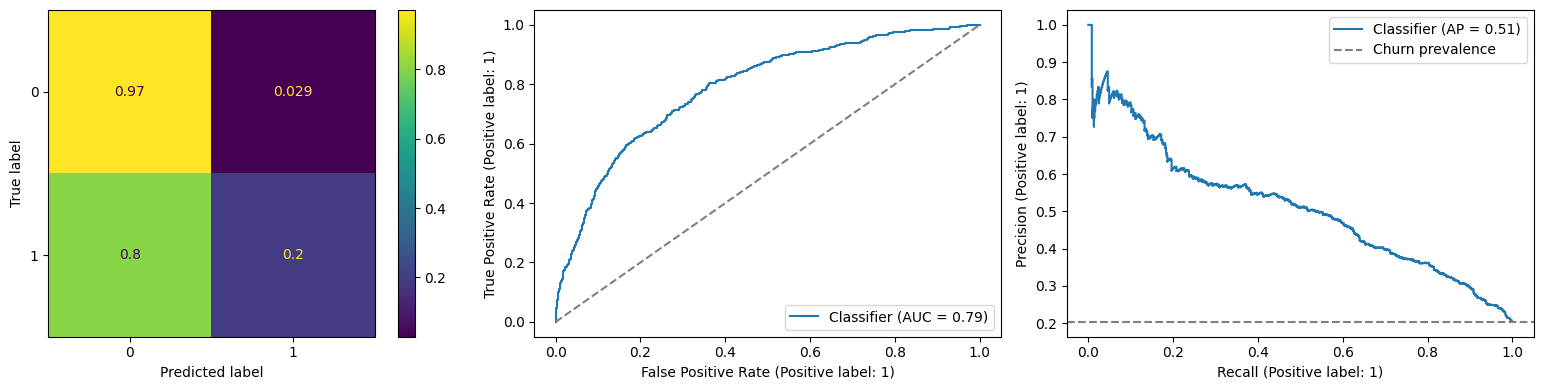

forest
              precision    recall  f1-score   support

           0       0.91      0.90      0.91      2389
           1       0.64      0.65      0.65       611

    accuracy                           0.85      3000
   macro avg       0.77      0.78      0.78      3000
weighted avg       0.86      0.85      0.85      3000



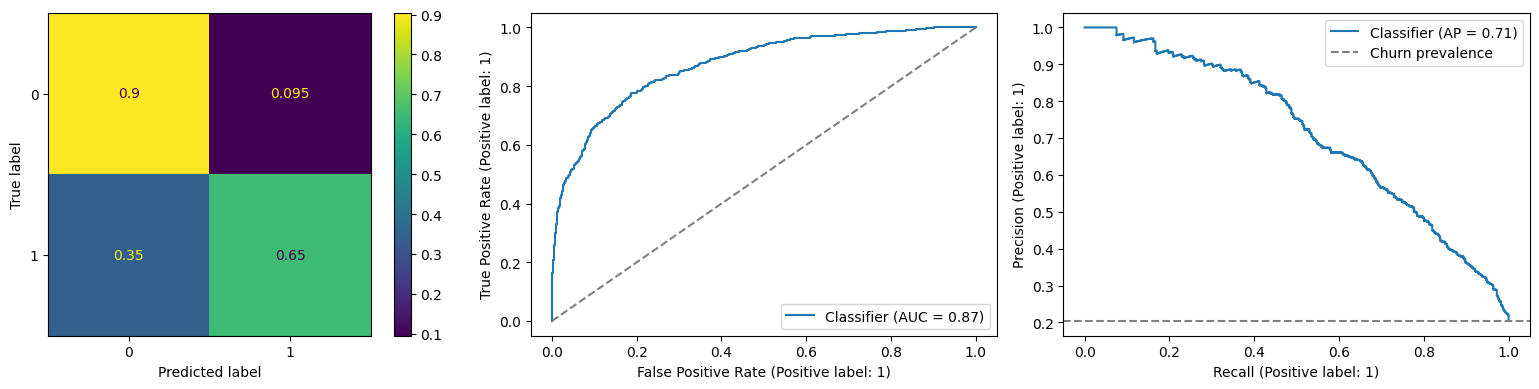

boosting
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      2389
           1       0.80      0.50      0.61       611

    accuracy                           0.87      3000
   macro avg       0.84      0.73      0.77      3000
weighted avg       0.87      0.87      0.86      3000



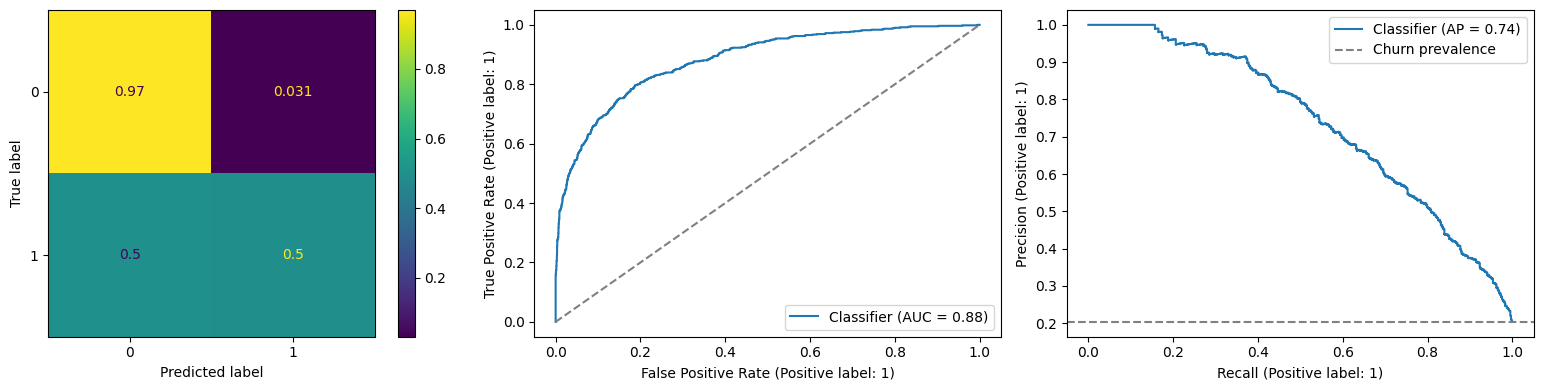

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,log_loss,brier_score
Prior baseline,0.7963,0.5000,0.0000,0.0000,0.0000,0.5000,0.2037,0.5054,0.1622
logistic,0.8130,0.5835,0.6316,0.1964,0.2996,0.7881,0.5100,0.4157,0.1313
forest,0.8537,0.7796,0.6369,0.6547,0.6457,0.8731,0.7135,0.3723,0.1141
boosting,0.8727,0.7331,0.8021,0.4975,0.6141,0.8822,0.7380,0.3183,0.0959


In [4]:
baseline_metrics, _, _ = evaluate_baseline(X_train, y_train, X_test, y_test)
test_results = {'Prior baseline': baseline_metrics}
for name, search in searches.items():
    metrics, report, probabilities = evaluate_model(search.best_estimator_, X_test, y_test)
    test_results[name] = metrics
    print(name)
    print(report)
    plot_evaluation(y_test, probabilities)
    plt.show()
display(pd.DataFrame(test_results).T.round(4))

## Outreach budgets: training-only nested cross-validation

A limited campaign should rank customers rather than assume a score of 0.5 is a
useful cutoff. For each model, three outer folds generate scores. Each outer fold
performs a new five-fold parameter search on its fitting rows. A customer's score
therefore comes from preprocessing and model selection that excluded them.

All 7,000 training customers receive one out-of-fold score. Test rows are excluded
from this analysis. Three-fold outer models train on two-thirds of these training
rows, so results are not measurements of the final full-training fitted model.
Scores from different outer models are pooled for exploratory ranking.

The charts show contact capacity versus precision and recall. Selecting a capacity
from these charts is policy development, not an independent final estimate.

logistic: outer fold 1/3 (five-fold inner search)


logistic: outer fold 2/3 (five-fold inner search)


logistic: outer fold 3/3 (five-fold inner search)


forest: outer fold 1/3 (five-fold inner search)


forest: outer fold 2/3 (five-fold inner search)


forest: outer fold 3/3 (five-fold inner search)


boosting: outer fold 1/3 (five-fold inner search)


boosting: outer fold 2/3 (five-fold inner search)


boosting: outer fold 3/3 (five-fold inner search)


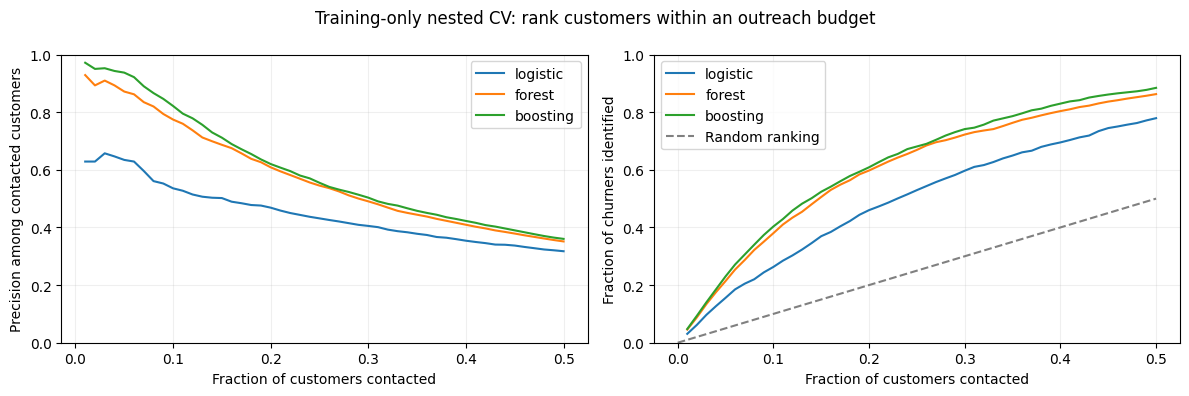

,model,requested_contact_fraction,flagged,precision,recall,lift_over_random,churners_identified_per_1000
4,logistic,0.05,350,0.6343,0.1557,3.1136,31.7143
9,logistic,0.10,700,0.5357,0.2630,2.6297,53.5714
19,logistic,0.20,1400,0.4686,0.4600,2.3001,93.7143
54,forest,0.05,350,0.8714,0.2139,4.2777,43.5714
59,forest,0.10,700,0.7743,0.3801,3.8008,77.4286
69,forest,0.20,1400,0.6086,0.5975,2.9874,121.7143
104,boosting,0.05,350,0.9371,0.2300,4.6003,46.8571
109,boosting,0.10,700,0.8214,0.4032,4.0323,82.1429
119,boosting,0.20,1400,0.6200,0.6087,3.0435,124.0000


In [5]:
capacity_tables = []
for name in ['logistic', 'forest', 'boosting']:
    scores = nested_training_scores(name, X_train, y_train)
    table = capacity_table(y_train, scores, np.round(np.arange(0.01, 0.51, 0.01), 2))
    table.insert(0, 'model', name)
    capacity_tables.append(table)
capacity_results = pd.concat(capacity_tables, ignore_index=True)
plot_capacity(capacity_results)
plt.show()
display(capacity_results[
    capacity_results.requested_contact_fraction.isin([0.05, 0.1, 0.2])
][['model', 'requested_contact_fraction', 'flagged', 'precision', 'recall',
   'lift_over_random', 'churners_identified_per_1000']].round(4))

## Selected portfolio scenario: contact the highest-risk 10%

Assume a fictional bank can contact 10% of its customers per campaign. This is a
reasonable illustrative middle scenario between a narrow 5% campaign and a
broader 20% campaign, not an observed business constraint or financial optimum.
Use gradient boosting as the demonstration model after exploratory comparisons.

Operationally, select exactly `floor(0.10 * population)` highest scores. Break ties
by stable input order, independent of outcomes. A fixed cutoff equal to the last
selected score could exceed capacity when customers tie. For a 10,000-customer
population the hypothetical budget is 1,000 contacts; the measured training-only
analysis below instead contains 7,000 customers and 700 contacts.

In [6]:
demo = capacity_results[
    (capacity_results.model == 'boosting') &
    (capacity_results.requested_contact_fraction == 0.10)
].iloc[0]
print(f"Contacts: {int(demo.flagged):,} of {int(demo.customers):,}")
print(f"Observed churners identified: {int(demo.true_positives):,}")
print(f"Nonchurners contacted: {int(demo.false_positives):,}")
print(f"Churners missed: {int(demo.false_negatives):,}")
print(f"Precision: {demo.precision:.1%}; recall: {demo.recall:.1%}")
print(f"Lift over random outreach: {demo.lift_over_random:.2f}×")

Contacts: 700 of 7,000
Observed churners identified: 575
Nonchurners contacted: 125
Churners missed: 851
Precision: 82.1%; recall: 40.3%
Lift over random outreach: 4.03×


## Conclusions and next steps

The 10% demonstration targets a smaller, higher-risk group while missing many
churners outside its capacity. Read the executed results above as evidence of
**targeting quality**, not saved customers or financial return. No outreach cost,
intervention effect, revenue, or monetary savings is established by this dataset.

Before real use, obtain an independent, preferably later-in-time cohort, freeze
model and capacity choices, assess calibration and subgroup behavior, and measure
the intervention's effect through an appropriate controlled evaluation. A model
that ranks observed churn well may still fail to identify customers whose churn
can be prevented.

The six regression tests cover training-only preprocessing, estimator evaluation,
probability-based AUC, nested-fold exclusion, exact capacity under ties, and metric
count consistency. Run `python -m unittest discover -s tests -v` from the repo root.